<a href="https://colab.research.google.com/github/felipef6/analiseFraudes/blob/main/deteccao_fraude_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de fraude em transações de cartão de crédito

Neste notebook eu treino modelos para detectar fraude em uma base real em que **só ~0,17% das transações são fraude**.
Como a acurácia engana nesse cenário, a métrica principal é o **recall da classe fraude**, sempre olhando junto
a **precisão** e o **F1**.

Etapas: **1. Explorar → 2. Preparar → 3. Treinar → 4. Avaliar → 5. Explicar**

In [ ]:
# Instalação (no Colab o xgboost já vem instalado, o shap nem sempre)
!pip install -q xgboost shap

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score,
)
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Explorar

Carrego a base direto pelo link (o arquivo **não** fica no repositório) e meço a proporção de fraudes.
As colunas `V1`–`V28` vêm de uma PCA (privacidade); só `Time`, `Amount` e `Class` estão na escala original.

In [ ]:
URL = "https://www.dropbox.com/s/b44o3t3ehmnx2b7/creditcard.csv?dl=1"
df = pd.read_csv(URL)

print("Formato:", df.shape)
display(df.head())
df.info()
print("\nValores nulos:", int(df.isnull().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))

Formato: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

,quantidade,%
Class,,
0,284315,99.8273
1,492,0.1727


Acurácia de um modelo que diz 'normal' para tudo: 99.8273%  -> recall da fraude = 0%


/tmp/ipykernel_732/2329656134.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Normal (0)", "Fraude (1)"])


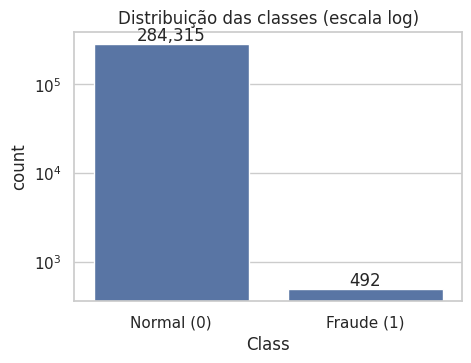

In [ ]:
contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True) * 100
display(pd.DataFrame({"quantidade": contagem, "%": proporcao}))

# Acurácia de um "modelo" que responde sempre "não é fraude"
acc_ingenua = (df["Class"] == 0).mean()
print(f"Acurácia de um modelo que diz 'normal' para tudo: {acc_ingenua:.4%}  -> recall da fraude = 0%")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="Class", data=df, ax=ax)
ax.set_yscale("log")
ax.set_xticklabels(["Normal (0)", "Fraude (1)"])
ax.set_title("Distribuição das classes (escala log)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


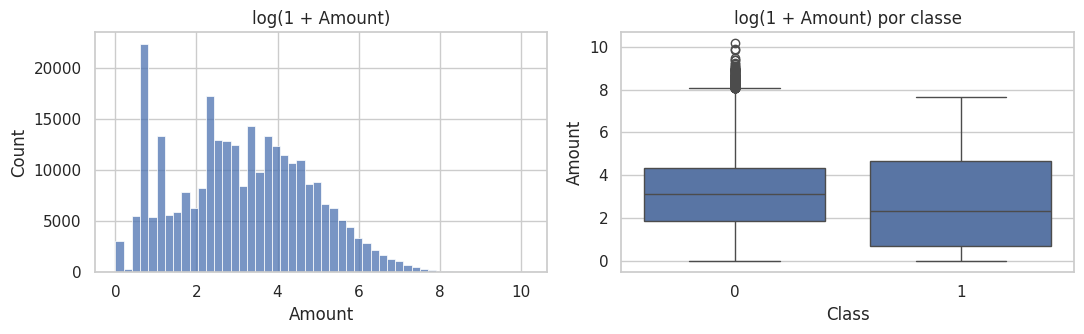

In [ ]:
# Valor da transação por classe
display(df.groupby("Class")["Amount"].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(np.log1p(df["Amount"]), bins=50, ax=axes[0])
axes[0].set_title("log(1 + Amount)")
sns.boxplot(x="Class", y=np.log1p(df["Amount"]), data=df, ax=axes[1])
axes[1].set_title("log(1 + Amount) por classe")
plt.tight_layout()
plt.show()

## 2. Preparar

Decisões desta etapa:

- **Remover duplicatas**: linhas idênticas poderiam cair em treino *e* teste e inflar as métricas.
- **Variáveis novas**: `Amount_log = log(1 + Amount)` (o valor é muito assimétrico) e `Hora_dia` (hora do dia a partir de `Time`, que está em segundos).
- **Split estratificado** (`stratify=y`) para manter a proporção de fraudes em todos os conjuntos.
  Uso **três conjuntos**: *treino* (ajusta o modelo), *validação* (escolhe o limiar de decisão) e *teste* (avaliação final, intocado).
- **StandardScaler ajustado só no treino** e aplicado em validação e teste, para não vazar informação.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

df["Amount_log"] = np.log1p(df["Amount"])
df["Hora_dia"] = (df["Time"] // 3600) % 24

X = df.drop(columns=["Class", "Amount"])
y = df["Class"]

# 80% treino+validação / 20% teste
X_tv, X_teste, y_tv, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# dentro do treino: 80% treino / 20% validação
X_treino, X_val, y_treino, y_val = train_test_split(
    X_tv, y_tv, test_size=0.20, stratify=y_tv, random_state=RANDOM_STATE)

# padronização (fit apenas no treino)
cols_escalar = ["Time", "Amount_log", "Hora_dia"]
scaler = StandardScaler().fit(X_treino[cols_escalar])


def aplicar_escala(X_):
    X_ = X_.copy()
    X_[cols_escalar] = scaler.transform(X_[cols_escalar])
    return X_


X_treino, X_val, X_teste = (aplicar_escala(d) for d in (X_treino, X_val, X_teste))

resumo = pd.DataFrame({
    "linhas": [len(y_treino), len(y_val), len(y_teste)],
    "fraudes": [int(y_treino.sum()), int(y_val.sum()), int(y_teste.sum())],
    "% fraude": [y_treino.mean() * 100, y_val.mean() * 100, y_teste.mean() * 100],
}, index=["treino", "validação", "teste"])
display(resumo)

,linhas,fraudes,% fraude
treino,181584,302,0.1663
validação,45396,76,0.1674
teste,56746,95,0.1674


## 3. Treinar

Comparo **regressão logística** (baseline), **Random Forest** e **XGBoost**.
Para lidar com o desbalanceamento uso o **peso das classes**:

- `class_weight="balanced"` na regressão logística;
- `class_weight="balanced_subsample"` na Random Forest;
- `scale_pos_weight = nº normais / nº fraudes` no XGBoost.

In [ ]:
peso_fraude = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f"scale_pos_weight (normais por fraude no treino): {peso_fraude:.1f}")

modelos = {
    "Regressão Logística": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=peso_fraude, tree_method="hist",
        eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE),
}

proba_val, proba_teste = {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    proba_val[nome] = modelo.predict_proba(X_val)[:, 1]
    proba_teste[nome] = modelo.predict_proba(X_teste)[:, 1]
    print(f"{nome}: treinado")

scale_pos_weight (normais por fraude no treino): 600.3
Regressão Logística: treinado


KeyboardInterrupt: 

### Métricas com o limiar padrão (0,5)

Função auxiliar que calcula as métricas da classe fraude (`Class = 1`).

In [ ]:
def metricas(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "limiar": limiar,
        "recall_fraude": recall_score(y_true, pred),
        "precisao_fraude": precision_score(y_true, pred, zero_division=0),
        "f1_fraude": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }


tab_05 = pd.DataFrame({n: metricas(y_teste, p, 0.5) for n, p in proba_teste.items()}).T
print("TESTE com limiar = 0,5")
display(tab_05)

TESTE com limiar = 0,5


,limiar,recall_fraude,precisao_fraude,f1_fraude,roc_auc,pr_auc
Regressão Logística,0.5000,0.8737,0.0510,0.0963,0.9621,0.6834


### Ajuste do limiar de decisão

O limiar de 0,5 não tem nada de especial. Em fraude, perder uma fraude (falso negativo) costuma custar mais do que
investigar uma transação normal (falso positivo), então escolho o limiar **na validação** assim:

> entre os limiares com `recall ≥ META_RECALL`, fico com o de **maior precisão**.
> Se nenhum atingir a meta, uso o limiar de maior F1.

Depois avalio no **teste**, que não participou de nenhuma escolha.

In [ ]:
META_RECALL = 0.85   # ajuste conforme a sua justificativa de negócio


def escolher_limiar(y_true, proba, recall_min=META_RECALL):
    prec, rec, lim = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]          # alinha com o vetor de limiares
    ok = rec >= recall_min
    if ok.any():
        i = np.argmax(np.where(ok, prec, -1))
    else:
        f1 = 2 * prec * rec / (prec + rec + 1e-12)
        i = np.argmax(f1)
    return float(lim[i])


limiares = {n: escolher_limiar(y_val, p) for n, p in proba_val.items()}
print("Limiares escolhidos na validação:")
for n, l in limiares.items():
    print(f"  {n}: {l:.4f}")

tab_val = pd.DataFrame({n: metricas(y_val, proba_val[n], limiares[n]) for n in modelos}).T
tab_final = pd.DataFrame({n: metricas(y_teste, proba_teste[n], limiares[n]) for n in modelos}).T

print("\nVALIDAÇÃO com limiar ajustado")
display(tab_val)
print("TESTE com limiar ajustado (resultado final)")
display(tab_final)

# modelo escolhido pelo F1 da validação (o teste fica só para reportar)
melhor = tab_val["f1_fraude"].idxmax()
print(f"\nMelhor modelo (F1 na validação): {melhor}")

Limiares escolhidos na validação:
  Regressão Logística: 0.9998


KeyError: 'Random Forest'

## 4. Avaliar

Relatório de classificação, matriz de confusão, curva ROC e curva de precisão × recall.
O foco é o **recall da fraude**.

In [ ]:
for nome in modelos:
    pred = (proba_teste[nome] >= limiares[nome]).astype(int)
    print("=" * 60)
    print(f"{nome}  (limiar = {limiares[nome]:.4f})")
    print(classification_report(y_teste, pred, target_names=["Normal", "Fraude"], digits=4))

Regressão Logística  (limiar = 0.9998)
              precision    recall  f1-score   support

      Normal     0.9996    0.9996    0.9996     56651
      Fraude     0.7766    0.7684    0.7725        95

    accuracy                         0.9992     56746
   macro avg     0.8881    0.8840    0.8861     56746
weighted avg     0.9992    0.9992    0.9992     56746



KeyError: 'Random Forest'

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, nome in zip(axes, modelos):
    pred = (proba_teste[nome] >= limiares[nome]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred),
                           display_labels=["Normal", "Fraude"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{nome}\nlimiar = {limiares[nome]:.3f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva ROC
for nome, p in proba_teste.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set(xlabel="Taxa de falsos positivos", ylabel="Recall (TPR)", title="Curva ROC")
axes[0].legend(loc="lower right")

# Curva Precisão x Recall (a mais informativa em base desbalanceada)
for nome, p in proba_teste.items():
    prec, rec, _ = precision_recall_curve(y_teste, p)
    axes[1].plot(rec, prec, label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")
    l = limiares[nome]
    axes[1].scatter(recall_score(y_teste, proba_teste[nome] >= l),
                    precision_score(y_teste, proba_teste[nome] >= l, zero_division=0),
                    s=60, zorder=5)
axes[1].axhline(y_teste.mean(), color="k", ls="--", alpha=0.5, label="Sorteio aleatório")
axes[1].set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão × Recall (pontos = limiar escolhido)")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# Efeito do limiar no melhor modelo: precisão, recall e F1 em função do limiar (validação)
prec, rec, lim = precision_recall_curve(y_val, proba_val[melhor])
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)

plt.figure(figsize=(8, 4))
plt.plot(lim, prec[:-1], label="Precisão")
plt.plot(lim, rec[:-1], label="Recall")
plt.plot(lim, f1, label="F1")
plt.axvline(limiares[melhor], color="k", ls="--", label=f"Limiar escolhido = {limiares[melhor]:.3f}")
plt.xlabel("Limiar de decisão")
plt.title(f"{melhor}: métricas × limiar (validação)")
plt.legend()
plt.show()

## Extra: undersampling × oversampling × peso das classes

Alternativas para equilibrar as classes **apenas no treino** (validação e teste ficam intactos),
comparadas com o XGBoost. Implementado à mão com pandas/NumPy, sem depender de bibliotecas extras.

- **Undersampling**: mantém todas as fraudes e sorteia o mesmo número de transações normais (descarta muita informação).
- **Oversampling**: repete aleatoriamente fraudes até igualar o número de normais (risco de decorar as fraudes repetidas).

In [ ]:
def subamostrar(X_, y_, seed=RANDOM_STATE):
    idx_f = y_.index[y_ == 1]
    idx_n = y_[y_ == 0].sample(len(idx_f), random_state=seed).index
    idx = idx_f.append(idx_n)
    return X_.loc[idx], y_.loc[idx]


def sobreamostrar(X_, y_, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    idx_n = y_.index[y_ == 0].to_numpy()
    idx_f = rng.choice(y_.index[y_ == 1].to_numpy(), size=len(idx_n), replace=True)
    idx = np.concatenate([idx_n, idx_f])
    return X_.loc[idx], y_.loc[idx]


def novo_xgb(**kw):
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                         colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                         n_jobs=-1, random_state=RANDOM_STATE, **kw)


estrategias = {
    "Peso das classes": (X_treino, y_treino, {"scale_pos_weight": peso_fraude}),
    "Undersampling": (*subamostrar(X_treino, y_treino), {}),
    "Oversampling": (*sobreamostrar(X_treino, y_treino), {}),
}

linhas = {}
for nome, (Xb, yb, kw) in estrategias.items():
    m = novo_xgb(**kw).fit(Xb, yb)
    l = escolher_limiar(y_val, m.predict_proba(X_val)[:, 1])
    linhas[nome] = metricas(y_teste, m.predict_proba(X_teste)[:, 1], l)
    linhas[nome]["linhas_treino"] = len(yb)

print("XGBoost, avaliado no TESTE com limiar ajustado na validação")
tab_balanceamento = pd.DataFrame(linhas).T
tab_balanceamento["linhas_treino"] = tab_balanceamento["linhas_treino"].astype(int)
display(tab_balanceamento)

## 5. Explicar

Primeiro a importância das variáveis (visão global) e depois o **SHAP** (visão global e por transação).
Uso o XGBoost para o SHAP porque o `TreeExplainer` é exato e rápido em modelos de árvore.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nome in zip(axes, ["Random Forest", "XGBoost"]):
    imp = pd.Series(modelos[nome].feature_importances_, index=X_treino.columns).nlargest(15)
    sns.barplot(x=imp.values, y=imp.index, ax=ax, color="steelblue")
    ax.set_title(f"Importância das variáveis: {nome}")
plt.tight_layout()
plt.show()

In [ ]:
xgb = modelos["XGBoost"]

# amostra do teste: todas as fraudes + 1.500 transações normais (SHAP em 56 mil linhas seria lento)
rng = np.random.RandomState(RANDOM_STATE)
idx_fraude = X_teste.index[(y_teste == 1).to_numpy()]
idx_normal = rng.choice(X_teste.index[(y_teste == 0).to_numpy()], size=1500, replace=False)
X_amostra = X_teste.loc[np.concatenate([idx_fraude, idx_normal])]

explainer = shap.TreeExplainer(xgb)
sv = explainer(X_amostra)

# visão global: quais variáveis mais pesam e em que direção
shap.plots.beeswarm(sv, max_display=15)

In [ ]:
# visão global resumida: impacto médio absoluto de cada variável
shap.plots.bar(sv, max_display=15)

In [ ]:
# visão local: por que ESTA transação foi marcada como fraude?
# (as fraudes ficam nas primeiras linhas da amostra)
i = 0
p = xgb.predict_proba(X_amostra.iloc[[i]])[0, 1]
print(f"Probabilidade de fraude: {p:.4f} | limiar: {limiares['XGBoost']:.4f} | "
      f"classe real: {int(y_teste.loc[X_amostra.index[i]])}")
shap.plots.waterfall(sv[i], max_display=12)

## Conclusões (use como base para o README)

Preencha com os **seus** números depois de rodar:

1. **Por que a acurácia engana**: um modelo que diz "normal" para tudo tem ~99,8% de acurácia e 0% de recall da fraude.
2. **Preparação**: duplicatas removidas, `Amount_log`, `Hora_dia`, split estratificado em treino/validação/teste, `StandardScaler` ajustado só no treino.
3. **Comparação**: tabela `tab_final` (recall, precisão e F1 da fraude por modelo) e curvas ROC / PR.
4. **Limiar**: escolhido na validação com meta de recall = `META_RECALL`; explique o trade-off entre fraudes pegas e alarmes falsos.
5. **SHAP**: quais variáveis (V14, V4, V12... costumam aparecer) mais empurram uma transação para "fraude".
6. **O que mudei em relação à Expert**: por exemplo, validação separada para o limiar, remoção de duplicatas, comparação de under/oversampling.